# **SIGK - Implementacja SRCNN do zwiększania rozdzielczości obrazu.**

In [1]:
# Implementacja w PyTorchu, początkowo próbowałem jeszcze się z TensorFlowem zmagać, ale stwierdziłem że tak będzie prościej jednak i bardziej intuicyjnie.

# Przygotowanie danych:
# 1. Z obrazu DIV2K wycinamy fragment HR 256x256 (8 stałych losowych cropów dla wybranego seedu - trening, CenterCrop - walidacja i test).
# 2. LR powstaje przez zmniejszenie fragmentu do 64x64 (lub 32x32): zastosowano metodę: cv2.resize, INTER_AREA. Dlatego, że INTER_CUBIC służy najlepiej do
# zwiększania obrazów.
# 3. Wejście sieci: LR powiększony z powrotem do 256x256: cv2.resize, INTER_CUBIC.
# 4. Metoda bazowa = ten sam obraz z kroku 3 (OpenCV, interpolacja bikubiczna).

### Literatura:
https://arxiv.org/pdf/2601.16413<br>
https://docs.pytorch.org/docs<br>
https://medium.com/coinmonks/review-srcnn-super-resolution-3cb3a4f67a7c<br>
https://medium.com/aimonks/cosine-annealing-enhancing-deep-learning-through-dynamic-learning-rate-adjustment-d60957fe7115<br>

In [2]:
!wget -nc http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip

--2026-11-02 14:45:06--  http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178, 2001:67c:10ec:36c2::178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip [following]
--2026-11-02 14:45:07--  https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3530603713 (3.3G) [application/zip]
Saving to: ‘DIV2K_train_HR.zip’

DIV2K_train_HR.zip  100%[===================>]   3.29G  37.2MB/s    in 92s     

2026-11-02 14:46:39 (36.6 MB/s) - ‘DIV2K_train_HR.zip’ saved [3530603713/3530603713]



In [3]:
!unzip -q -n DIV2K_train_HR.zip -d ./DIV2K

In [4]:
!ls DIV2K/DIV2K_train_HR/

0001.png  0101.png  0201.png  0301.png	0401.png  0501.png  0601.png  0701.png
0002.png  0102.png  0202.png  0302.png	0402.png  0502.png  0602.png  0702.png
0003.png  0103.png  0203.png  0303.png	0403.png  0503.png  0603.png  0703.png
0004.png  0104.png  0204.png  0304.png	0404.png  0504.png  0604.png  0704.png
0005.png  0105.png  0205.png  0305.png	0405.png  0505.png  0605.png  0705.png
0006.png  0106.png  0206.png  0306.png	0406.png  0506.png  0606.png  0706.png
0007.png  0107.png  0207.png  0307.png	0407.png  0507.png  0607.png  0707.png
0008.png  0108.png  0208.png  0308.png	0408.png  0508.png  0608.png  0708.png
0009.png  0109.png  0209.png  0309.png	0409.png  0509.png  0609.png  0709.png
0010.png  0110.png  0210.png  0310.png	0410.png  0510.png  0610.png  0710.png
0011.png  0111.png  0211.png  0311.png	0411.png  0511.png  0611.png  0711.png
0012.png  0112.png  0212.png  0312.png	0412.png  0512.png  0612.png  0712.png
0013.png  0113.png  0213.png  0313.png	0413.png  0513.png  0613.

In [5]:
!wget -nc http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
!unzip -q -n DIV2K_valid_HR.zip -d ./DIV2K

--2026-11-02 14:47:06--  http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178, 2001:67c:10ec:36c2::178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip [following]
--2026-11-02 14:47:06--  https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 448993893 (428M) [application/zip]
Saving to: ‘DIV2K_valid_HR.zip’

DIV2K_valid_HR.zip  100%[===================>] 428.19M  37.2MB/s    in 12s     

2026-11-02 14:47:19 (34.8 MB/s) - ‘DIV2K_valid_HR.zip’ saved [448993893/448993893]



In [6]:
!ls DIV2K/DIV2K_valid_HR/

0801.png  0814.png  0827.png  0840.png	0853.png  0866.png  0879.png  0892.png
0802.png  0815.png  0828.png  0841.png	0854.png  0867.png  0880.png  0893.png
0803.png  0816.png  0829.png  0842.png	0855.png  0868.png  0881.png  0894.png
0804.png  0817.png  0830.png  0843.png	0856.png  0869.png  0882.png  0895.png
0805.png  0818.png  0831.png  0844.png	0857.png  0870.png  0883.png  0896.png
0806.png  0819.png  0832.png  0845.png	0858.png  0871.png  0884.png  0897.png
0807.png  0820.png  0833.png  0846.png	0859.png  0872.png  0885.png  0898.png
0808.png  0821.png  0834.png  0847.png	0860.png  0873.png  0886.png  0899.png
0809.png  0822.png  0835.png  0848.png	0861.png  0874.png  0887.png  0900.png
0810.png  0823.png  0836.png  0849.png	0862.png  0875.png  0888.png
0811.png  0824.png  0837.png  0850.png	0863.png  0876.png  0889.png
0812.png  0825.png  0838.png  0851.png	0864.png  0877.png  0890.png
0813.png  0826.png  0839.png  0852.png	0865.png  0878.png  0891.png


In [7]:
!pip install lpips

In [8]:
import os
from torch.utils.data import Dataset
from pathlib import Path
from PIL import Image
import cv2
import random
from torchvision.transforms import v2
from torch.utils.data import ConcatDataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
import kagglehub
import gc
from google.colab import files
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np
import lpips
import math
from tqdm.auto import tqdm
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

### Parametry sieci neuronowej i środowiska

In [40]:
LOWRES = '64x64' #@param ["64x64", "32x32"]
if LOWRES == '64x64':
  LR_SIZE = (64,64) # Rozdzielczość obrazka los-resolution
elif LOWRES == '32x32':
  LR_SIZE = (32,32)

HR_SIZE = (256,256) # Rozdzielczość docelowa high-resolution.
NUM_EPOCHS = 30 #@param {type:"integer"}
# Przy obecnej optymalizacji - jedna epoka zajmuje około 60 s.
BATCH_SIZE = 16 #@param {type:"integer"}
NUM_WORKERS = 2
LR = 1e-4 # Początkowy learning rate siatki.
LR_MIN = 0 # Minimalny learning rate do którego możemy zejść stosując CosineAnnealing. Tutaj po prostu zostawię to jako domyślna wartość 0.
EPS = 1e-4 # Epsilon do f. straty Charboniera (aby nie zerowały się gradienty + zapewniamy stabilność numeryczną).
UPSCALE_FACTOR = HR_SIZE[0] / LR_SIZE[0]
SEED = 3984 #@param {type:"slider", min:0, max:10000, step:1}
NUM_CROPS = 1

In [56]:
def extract_crops(root_directory, num_crops=NUM_CROPS, size=HR_SIZE[0], center=False, seed=SEED): # Ustawiamy katalog źródłowy, liczbę wycinków (im więcej tym więcej danych do treningu).
  # size jest rozmiarem docelowym obrazka HR, czyli np. 256px. Możemy również ustawić ziarno według którego robimy losowy wycinek.
  rng = np.random.default_rng(seed)
  files = sorted(f for f in os.listdir(root_directory) if f.lower().endswith(('.png', '.jpg', '.jpeg'))) # Zbieramy wszystkie pliki o oczekiwanym rozszerzeniu.
  crops = np.empty((len(files) * num_crops, size, size, 3), np.uint8) # Zwracamy tablicę wycinków (co mamy wyciąć)
  k = 0
  for f in tqdm(files):
    img = np.array(Image.open(os.path.join(root_directory, f)).convert('RGB'))
    h, w = img.shape[:2]
    for _ in range(num_crops):
      if center:
        y, x = int(np.floor((h - size) / 2)), int(np.floor((w - size) / 2))
        # To po prostu centralny wycinek - przykładowo dla obrazu 1024 x 1024 i docelowego 256 x 256:
        # floor[ (1024 - 256) / 2 ] = floor(768 / 2), czyli usuwamy górny i dolny margines
        # Dostajemy punkt początkowy floor(384) = 384. Od tego punktu zaczynamy wycinać względem osi Y.
        # Potem robimy analogicznie dla osi X, ostatecznie dostajemy wycinek 256 x 256 z wcześniej wspomnianym marginesem.
      else:
        y, x = rng.integers(0, h - size + 1), rng.integers(0, w - size + 1)
        # Losujemy punkty początkowe wycinka od 0 do np. 1024 - 256 + 1 = od 0 do 769.
        # Odejmujemy 256 aby na pewno dało się wyciąć obszar o minimalnej wysokości 256 px.
      crops[k] = img[y:y + size, x:x + size]
      # Kopiujemy do tablicy obszar zainteresowania.
      k += 1
  return crops

class CropDataset(Dataset):
  def __init__(self, hr_crops, lr_size=LR_SIZE, augment=False):
    self.hr, self.lr_size, self.augment = hr_crops, lr_size, augment

  def __len__(self):
    return len(self.hr)

  def __getitem__(self, idx):
    hr_img = self.hr[idx]

    if self.augment: # Domyślnie nie dokonujemy augmentacji danych, ale w celu zapobiegnięcia przeuczenia możemy dodać następujące operacje:
      # Horizontal flip
      # Vertical Flip
      # Rotation (0, 1, 2 ,3-krotna)
      # Włączając rozszerzenie zbioru danych pseudolosowo dodajemy modyfikację.
      if random.random() < 0.5: hr_img = hr_img[:, ::-1]
      if random.random() < 0.5: hr_img = hr_img[::-1]
      hr_img = np.rot90(hr_img, random.randint(0, 3))
    hr_img = np.ascontiguousarray(hr_img)
    # As C-Contigous Array pozwala przekształcić widok (uzyskany np. przez odwórcenie bajtów obrazka operacją ::-1) w zwykłą *ciągłą* tablicę.
    lr_img = cv2.resize(hr_img, self.lr_size, interpolation=cv2.INTER_AREA) # Zmniejszamy obraz, który będzie odwzorowywany w SR. Tutaj do zmniejszania zalecane jest stosowanie INTER_AREA.
    lr_upscaled = cv2.resize(lr_img, (hr_img.shape[1], hr_img.shape[0]), interpolation=cv2.INTER_CUBIC) # A następnie go zwiększamy metodą bikubiczną...
    to_pt = lambda a: torch.from_numpy(a).permute(2, 0, 1).float().div(255) # I zmieniamy format do PyTorcha. Głównie kwestia podmiany kanałów i normalizacji do float32.
    # PyTorch musi wczytać kanały jako C,H,W - domyślnie ładujemy obrazy jako H,W,C. Permutacja zamienia kolejność.
    return to_pt(lr_upscaled), to_pt(hr_img)

In [57]:
base_path = kagglehub.dataset_download("asilva1691/bsd100") # Pobieramy dataset BSD100, to po prostu test.
hr_test_path = os.path.join(base_path, "bsd100", "bicubic_2x", "train", "HR")
hr_val_path = os.path.join(base_path, "bsd100", "bicubic_2x", "val", "HR")

train_hr_crops = extract_crops('./DIV2K/DIV2K_train_HR', num_crops=8)
val_hr_crops = extract_crops('./DIV2K/DIV2K_valid_HR', center=True)
test_hr_crops = np.concatenate([extract_crops(hr_test_path, center=True), extract_crops(hr_val_path, center=True)])
print(train_hr_crops.shape, val_hr_crops.shape, test_hr_crops.shape)

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/80 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

(6400, 256, 256, 3) (100, 256, 256, 3) (100, 256, 256, 3)


In [58]:
train_dataset = CropDataset(train_hr_crops, lr_size=LR_SIZE, augment=True) # Włączamy augmentację danych dla zbioru treningowego.
val_dataset = CropDataset(val_hr_crops, lr_size=LR_SIZE)
test_dataset = CropDataset(test_hr_crops, lr_size=LR_SIZE)

for name in ('train_loader', 'val_loader'): # Mamy dwa wątki do ładowania danych (train, val loader), jeśli odpalamy nową sesję usuwamy stare loadery.
    if name in globals():
        del globals()[name]
gc.collect()

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, persistent_workers=True)
bsd100_test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False) # Combined Test Loader to po prostu scalenie BSD100 w całość, może to lepiej tak nazwać. Po prostu Benchmark.
print(len(train_dataset), len(val_dataset), len(test_dataset))

6400 100 100


#Super-Resolution Convolutional Neural Network (SRCNN):

### Moduły dodatkowe - Cosine CNN for Super Resolution:<br>
Architektura bazowana na podstawie:<br>
https://arxiv.org/pdf/2601.16413

In [59]:
class OEB(nn.Module):
  def __init__(self, channels):
    super().__init__()
    self.conv3x3 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
    self.conv1x3 = nn.Conv2d(channels, channels, kernel_size=(1,3), padding=(0,1))
    self.conv3x1 = nn.Conv2d(channels, channels, kernel_size=(3,1), padding=(1,0))
    self.activation = nn.ReLU()
  def forward(self,x):
    out1 = self.conv3x3(x)
    out2 = self.conv1x3(x)
    out3 = self.conv3x1(x)
    sum_out = out1 + out2 + out3 + x
    return self.activation(sum_out)

In [60]:
class EEB(nn.Module):
  def __init__(self, channels):
    super().__init__()
    self.conv_block = nn.Sequential(
        nn.Conv2d(channels, channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(channels, channels, kernel_size=3, padding=1)
    )
    self.activation = nn.ReLU()
  def forward(self,x):
    out = self.conv_block(x)
    return self.activation(out+x)

In [61]:
class CosineSRCNN(nn.Module):
  def __init__(self, channels=64):
    super().__init__()
    # Przechodzimy z 3 kanałów wejściowych (RGB)
    self.head = nn.Conv2d(3, channels, kernel_size=3, padding=1)
    self.body = nn.Sequential(
        OEB(channels),
        EEB(channels),
        OEB(channels),
        EEB(channels)
    )
    # Rekonstrukcja obrazu po ekstrakcji cech asymetrycznych (OEB) i stabilizacji (EEB)
    self.tail = nn.Conv2d(channels, 3, kernel_size = 3, padding=1)
  def forward(self,x):
    features = self.head(x)
    detail_features = self.body(features)
    return self.tail(detail_features) + x

### Klasyczny moduł SRCNN
Klasyczna architektura sieci wzorowana na:
https://medium.com/coinmonks/review-srcnn-super-resolution-3cb3a4f67a7c

In [62]:
class SRCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extraction = nn.Sequential(
      # Na początku mamy 3 kanały wejściowe RGB, stosujemy 64 filtry o rozmiarze kernela 9x9.
      nn.Conv2d(in_channels=3, out_channels=64, kernel_size=9, padding=4),
      nn.ReLU(),
      nn.Conv2d(in_channels=64, out_channels=32, kernel_size=1, padding=0),
      nn.ReLU(),
      nn.Conv2d(in_channels=32, out_channels=3, kernel_size=5, padding=2) # Dajemy na wyjście RGB - dobór paddingu jest szczerze bazowany na artykule
      # ale idea jest mniej więcej taka, że obraz wejściowy jest rozdzielczości M x M i na wyjściu mamy tą samą rozdzielczość.
    )
    nn.init.zeros_(self.feature_extraction[-1].weight)
    nn.init.zeros_(self.feature_extraction[-1].bias) # Początkowa inicjalizacja zerami dla biasów i wag.
    # Chcemy na początku treningu przekazać do sieci niezmodyfikowany obrazek, dzięki temu funkcja straty nie robi gwałtownych skoków.

  def forward(self,x):
    return x + self.feature_extraction(x)

  @torch.no_grad()
  def predict(self, x):
    return torch.clamp(self.forward(x), 0.0, 1.0)

In [63]:
class CharbonnierLoss(nn.Module): # Funkcja straty Charbonniera, podobna do L1 ale zapewnia większą stabilność numeryczną.
  def __init__(self, eps=EPS):    # Dla zadania SR strata MSE generuje wyblurrowany obraz, nie jest to najlepszy wybór.
                                  # W artykule dla CosineSRCNN stosowane jest zwykłe MAE (L1).
    super(CharbonnierLoss, self).__init__()
    self.eps = eps

  def forward(self, prediction, target):
    diff = prediction - target
    loss = torch.mean(torch.sqrt(diff * diff + self.eps * self.eps))
    return loss

### Trening sieci neuronowej

In [64]:
def run_epoch(model, loader, criterion, optimizer = None):
  training = optimizer is not None
  model.train(training)
  total_loss = 0.0 # Total lub running loss, chodzi o akumulację kosztu.
  with torch.set_grad_enabled(training):
    for lr_imgs, hr_imgs in loader:
      lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)
      loss = criterion(model(lr_imgs), hr_imgs) # Criterion to po prostu klasa, którą będziemy wykorzystywać do obliczania funkcji kosztu.
      if training:
        optimizer.zero_grad()
        loss.backward()
        optimizer.step() # Aktualizujemy wagi optymalizatora
      total_loss += loss.item() * lr_imgs.size(0)
  return total_loss / len(loader.dataset)

In [65]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # GPU albo CPU jeśli pierwsza opcja niedostępna.
model_name = "CosineSRCNN" #@param ["SRCNN", "CosineSRCNN"]
criterion_name = "Charbonnier" #@param ["MAE", "MSE", "Charbonnier"]

if model_name == "SRCNN":
  model = SRCNN().to(device)
elif model_name == "CosineSRCNN":
  model = CosineSRCNN().to(device)

if torch.cuda.device_count() > 1:
    print(f"Found {torch.cuda.device_count()} GPU's. Enabling Multi-GPU mode.")
    model = nn.DataParallel(model)

if criterion_name == "MAE":
  criterion = nn.L1Loss().to(device)
if criterion_name == "MSE":
  criterion = nn.MSELoss().to(device)
elif criterion_name == "Charbonnier":
  criterion = CharbonnierLoss(eps=EPS).to(device)

CKPT_PATH = f"./{model_name}_x{UPSCALE_FACTOR}_best.pth"
load_checkpoint = False  #@param {type:"boolean"}
if load_checkpoint:
  model.load_state_dict(torch.load(CKPT_PATH, weights_only=True))

Found 2 GPU's. Enabling Multi-GPU mode.


In [66]:
baseline_val_loss = run_epoch(nn.Identity(), val_loader, criterion)
# Macierz jednostkowa i odpalamy pojedynczą epokę aby sprawdzić jaki jest loss dla Bicubic.

Cosine Annealing:<br>
https://medium.com/aimonks/cosine-annealing-enhancing-deep-learning-through-dynamic-learning-rate-adjustment-d60957fe7115

In [67]:
train_losses = []
val_losses = []

best_val_loss = float('inf')

optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999), eps=1e-8) # Klasyczny Adam jako optimizer.
scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=LR_MIN) # Automatyczne 'ścinanie' learning rate w trakcie treningu.

print("Started training model...")
for epoch in range(NUM_EPOCHS):
  train_loss = run_epoch(model, train_loader, criterion, optimizer)
  scheduler.step()
  val_loss = run_epoch(model, val_loader, criterion)
  train_losses.append(train_loss)
  val_losses.append(val_loss)
  print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}"
        f" (Bicubic: {baseline_val_loss:.6f}) | LR: {scheduler.get_last_lr()[0]:.1e}")
  if val_loss < best_val_loss:
    best_val_loss = val_loss
    torch.save({'epoch': epoch + 1, 'model_state_dict': model.state_dict(),
      'optimizer_state_dict': optimizer.state_dict(),
      'train_loss': train_loss, 'val_loss': val_loss}, f'{model_name}_x{UPSCALE_FACTOR}_best.pth') # Zapisywanie najlepszego checkpointu po treningu.

Started training model...
Epoch 1/30 | Train Loss: 0.033115 | Val Loss: 0.038631 (Bicubic: 0.039052) | LR: 1.0e-04
Epoch 2/30 | Train Loss: 0.030490 | Val Loss: 0.037525 (Bicubic: 0.039052) | LR: 9.9e-05
Epoch 3/30 | Train Loss: 0.029929 | Val Loss: 0.037149 (Bicubic: 0.039052) | LR: 9.8e-05
Epoch 4/30 | Train Loss: 0.029718 | Val Loss: 0.036929 (Bicubic: 0.039052) | LR: 9.6e-05
Epoch 5/30 | Train Loss: 0.029502 | Val Loss: 0.036768 (Bicubic: 0.039052) | LR: 9.3e-05
Epoch 6/30 | Train Loss: 0.029379 | Val Loss: 0.036583 (Bicubic: 0.039052) | LR: 9.0e-05
Epoch 7/30 | Train Loss: 0.029257 | Val Loss: 0.036421 (Bicubic: 0.039052) | LR: 8.7e-05
Epoch 8/30 | Train Loss: 0.029158 | Val Loss: 0.036301 (Bicubic: 0.039052) | LR: 8.3e-05
Epoch 9/30 | Train Loss: 0.029065 | Val Loss: 0.036166 (Bicubic: 0.039052) | LR: 7.9e-05
Epoch 10/30 | Train Loss: 0.028952 | Val Loss: 0.036051 (Bicubic: 0.039052) | LR: 7.5e-05
Epoch 11/30 | Train Loss: 0.028886 | Val Loss: 0.036023 (Bicubic: 0.039052) | LR: 7

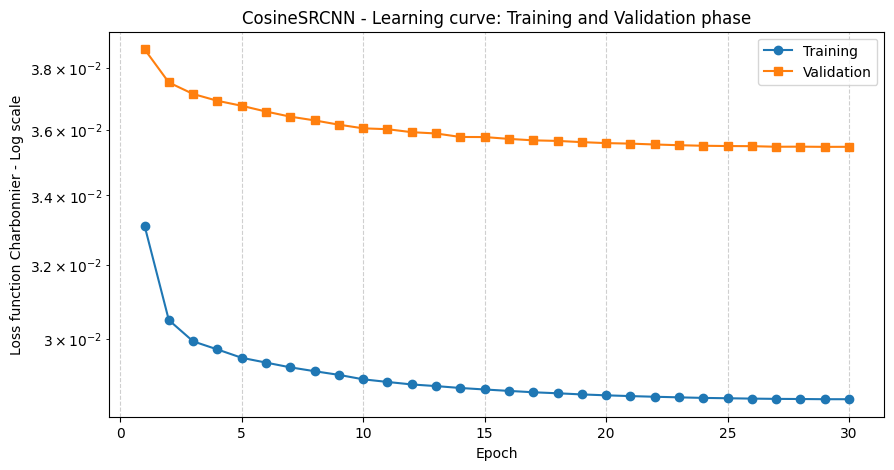

In [68]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, label='Training', marker='o')
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, label='Validation', marker='s')

plt.yscale('log')

plt.xlabel('Epoch')
plt.ylabel(f'Loss function {criterion_name} - Log scale')
plt.title(f'{model_name} - Learning curve: Training and Validation phase')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig(f"train_val_diagram_{model_name}.png")
plt.show()

# Ocena wyników przy pomocy zbioru BSD100 oraz metryk ewaluacyjnych

In [70]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if model_name == "SRCNN":
  eval_model = SRCNN().to(device)
else:
  eval_model = CosineSRCNN().to(device)
ckpt = torch.load(f'{model_name}_x{UPSCALE_FACTOR}_best.pth', map_location=device)
sd = {k.removeprefix("module."): v for k, v in ckpt['model_state_dict'].items()}
eval_model.load_state_dict(sd)
eval_model.eval()

loss_fn_lpips = lpips.LPIPS(net='alex').to(device).eval() # AlexNet albo VGG
psnr_model, ssim_model, lpips_model = [], [], []
psnr_base, ssim_base, lpips_base = [], [], []

print("Starting evaluation:")

with torch.no_grad():
    for lr_imgs, hr_imgs in bsd100_test_loader:
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)

        sr_imgs = eval_model(lr_imgs).clamp(0, 1) # Obrazki powiększone SR
        base_imgs = F.interpolate(lr_imgs, size=hr_imgs.shape[2:], mode='bicubic', align_corners=False).clamp(0, 1)

        for i in range(hr_imgs.size(0)):
            hr_np = hr_imgs[i].cpu().permute(1, 2, 0).numpy() # RGB, float32
            sr_np = sr_imgs[i].cpu().permute(1, 2, 0).numpy()

            # Ewaluacji dokonujemy na kanale Y (luminancja), zatem musimy mieć konwersję na YCrCb / YUV:
            hr_y = cv2.cvtColor(hr_np, cv2.COLOR_RGB2YCrCb)[:,:,0]
            sr_y = cv2.cvtColor(sr_np, cv2.COLOR_RGB2YCrCb)[:,:,0]

            base_np = base_imgs[i].cpu().permute(1, 2, 0).numpy()
            base_y = cv2.cvtColor(base_np, cv2.COLOR_RGB2YCrCb)[:,:,0]

            psnr_model.append(peak_signal_noise_ratio(hr_y, sr_y, data_range=1.0))
            psnr_base.append(peak_signal_noise_ratio(hr_y, base_y, data_range=1.0)) # PSNR porównujemy dla kanału Y. Gdybyśmy użyli RGB uśrednilibyśmy sygnał z poszczególnych kanałów barwnych.

            ssim_model.append(structural_similarity(hr_y, sr_y, data_range=1.0))
            ssim_base.append(structural_similarity(hr_y, base_y, data_range=1.0)) # SSIM podobnie, LPIPS pozostaje jako RGB.

            hr_lpips = hr_imgs[i:i+1] * 2.0 - 1.0
            sr_lpips = sr_imgs[i:i+1] * 2.0 - 1.0
            base_lpips = base_imgs[i:i+1] * 2.0 - 1.0

            lpips_model.append(loss_fn_lpips(sr_lpips, hr_lpips).item())
            lpips_base.append(loss_fn_lpips(base_lpips, hr_lpips).item())

print("\nBenchmark evaluation on BSD100 dataset results:")
print(f"SRCNN Upscale | {np.mean(psnr_model):.6f} dB | SSIM: {np.mean(ssim_model):.6f} | LPIPS: {np.mean(lpips_model):.6f}")
print(f"Bicubic Upscale | PSNR: {np.mean(psnr_base):.6f} dB | SSIM: {np.mean(ssim_base):.6f} | LPIPS: {np.mean(lpips_base):.6f}")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:00<00:00, 254MB/s] 


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
Starting evaluation:

Benchmark evaluation on BSD100 dataset results:
SRCNN Upscale | 24.684386 dB | SSIM: 0.698341 | LPIPS: 0.404314
Bicubic Upscale | PSNR: 24.022980 dB | SSIM: 0.660729 | LPIPS: 0.519213


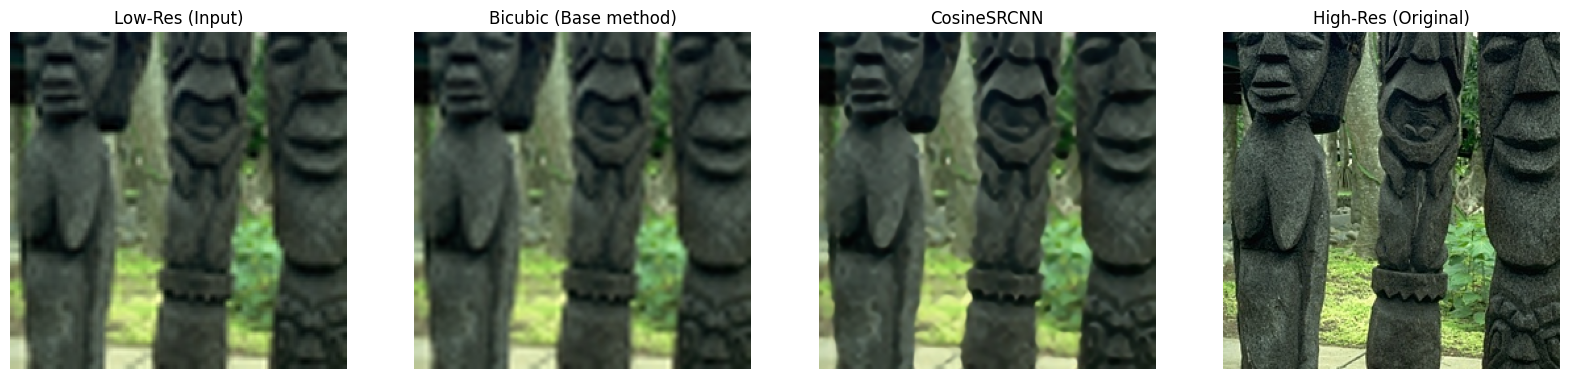

In [71]:
model.eval()
with torch.no_grad():
    lr_imgs, hr_imgs = next(iter(bsd100_test_loader))
    lr_imgs, hr_imgs = lr_imgs.to(device), hr_imgs.to(device)

    sr_imgs = model(lr_imgs).clamp(0, 1)
    base_imgs = F.interpolate(lr_imgs, size=hr_imgs.shape[2:], mode='bicubic', align_corners=False).clamp(0, 1)

hr_show = hr_imgs[0].cpu().permute(1, 2, 0).numpy()
sr_show = sr_imgs[0].cpu().permute(1, 2, 0).numpy()
base_show = base_imgs[0].cpu().permute(1, 2, 0).numpy()
lr_show = lr_imgs[0].cpu().permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(lr_show, interpolation='nearest')
axes[0].set_title("Low-Res (Input)")
axes[1].imshow(base_show)
axes[1].set_title(f"Bicubic (Base method)")
axes[2].imshow(sr_show)
axes[2].set_title(f"{model_name}")
axes[3].imshow(hr_show)
axes[3].set_title("High-Res (Original)")

for ax in axes:
    ax.axis('off')
plt.savefig(f"train_results_{model_name}.png")
plt.show()

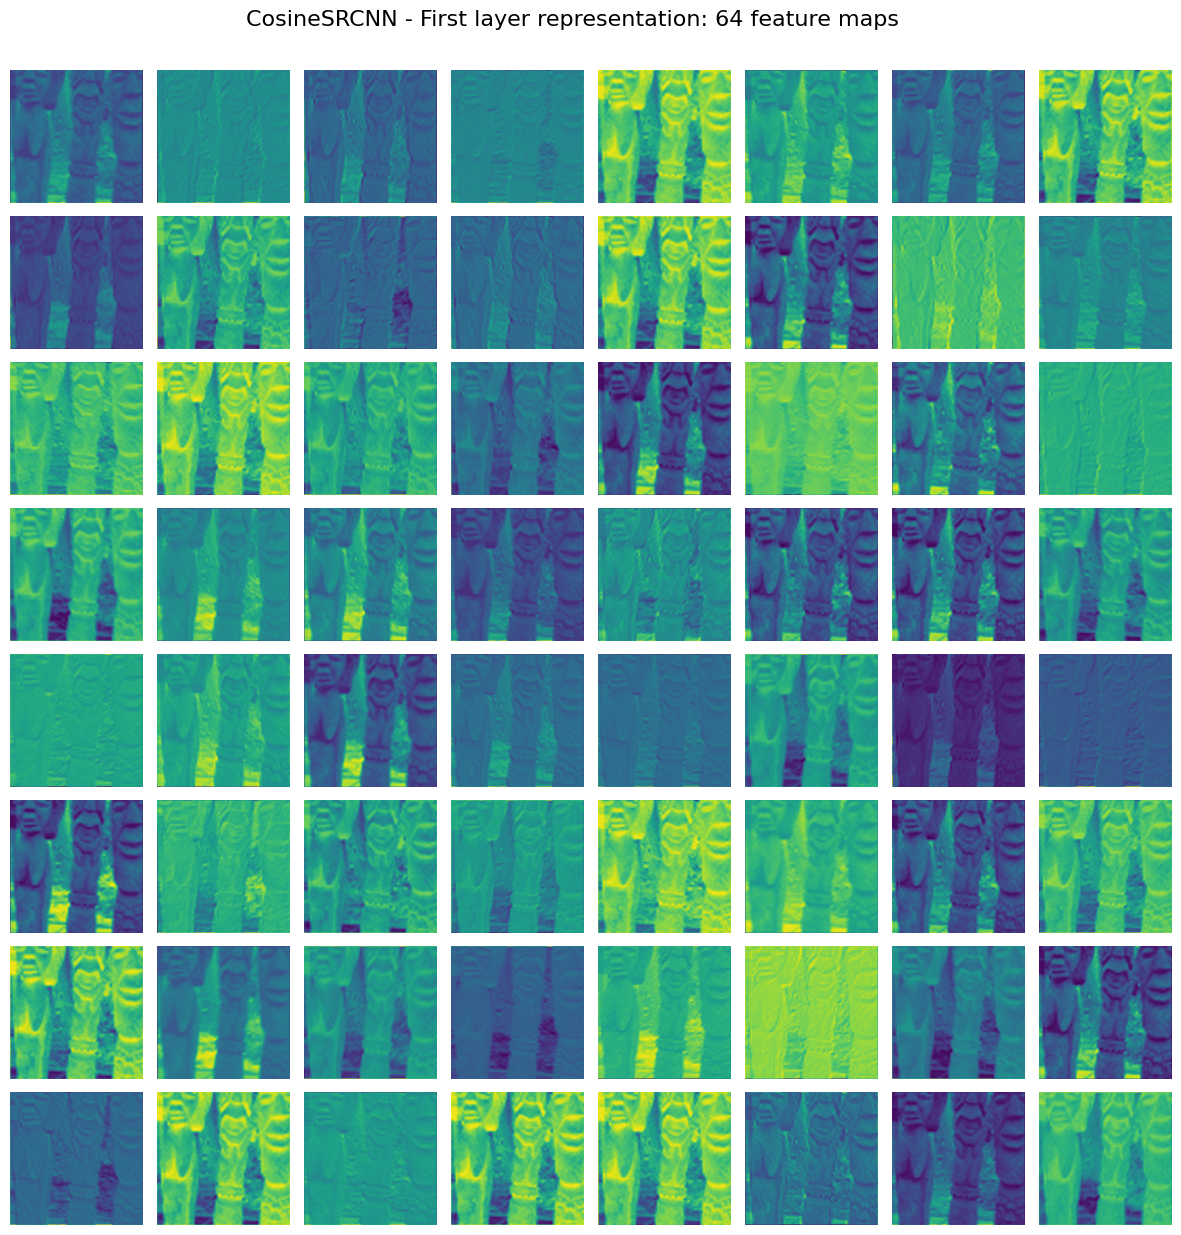

In [74]:
eval_model.eval()

with torch.no_grad():
    lr_imgs, _ = next(iter(bsd100_test_loader))
    lr_imgs = lr_imgs.to(device)
    first_layer = eval_model.feature_extraction[0] if model_name == "SRCNN" else eval_model.head
    feature_maps = first_layer(lr_imgs)

features_np = feature_maps[0].cpu().numpy()
num_features = features_np.shape[0]
grid_size = int(math.ceil(math.sqrt(num_features)))

fig, axes = plt.subplots(grid_size, grid_size, figsize=(15, 15))
fig.subplots_adjust(hspace=0.1, wspace=0.1)

for i, ax in enumerate(axes.flat):
    if i < num_features: # Wyświetlanie mapy cech (jedna z 64 dla SRCNN)
        ax.imshow(features_np[i], cmap='viridis')
        ax.axis('off')
    else:
        ax.axis('off')

plt.suptitle(f"{model_name} - First layer representation: 64 feature maps", fontsize=16, y=0.92)
plt.savefig(f"feature_maps_{model_name}.png") # Najpierw zapis potem show.
plt.show()